# Лабораторна робота №4. Регресійні моделі: глибоке дослідження

**Датасет:** Car Price Prediction Multiple Linear Regression  
https://www.kaggle.com/datasets/hellbuoy/car-price-prediction?select=CarPrice_Assignment.csv

**Мета роботи:** виконати підготовку даних, побудувати та порівняти регресійні моделі для прогнозування ціни автомобіля, оцінити їх якість і проаналізувати отримані результати.

> У шаблоні наведено лише умови завдань. Реалізацію необхідно виконати самостійно у порожніх комірках.


## 1. Завантаження та первинний аналіз даних

Завантажити датасет та виконати його первинний огляд:
- визначити кількість об'єктів і ознак;
- переглянути назви стовпців;
- визначити типи даних;
- визначити цільову змінну;
- вивести основні статистичні характеристики даних.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler,
    PowerTransformer
)

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error
)

import warnings
warnings.filterwarnings("ignore")

print("Бібліотеки успішно підключено.")

Бібліотеки успішно підключено.


In [2]:
url = "https://raw.githubusercontent.com/jey1987/DATA605/master/CarPrice_Assignment.csv"

df = pd.read_csv(url)

print("Дані успішно завантажено.")
print("Розмір датасету:", df.shape)

display(df.head())


Дані успішно завантажено.
Розмір датасету: (205, 26)


,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0


In [3]:
print("Назви стовпців:")
print(df.columns.tolist())

print("\nТипи даних:")
print(df.dtypes)

print("\nЦільова змінна: price")

print("\nОсновні статистичні характеристики:")
display(df.describe().T)

Назви стовпців:
['car_ID', 'symboling', 'CarName', 'fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 'enginetype', 'cylindernumber', 'enginesize', 'fuelsystem', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg', 'price']

Типи даних:
car_ID                int64
symboling             int64
CarName              object
fueltype             object
aspiration           object
doornumber           object
carbody              object
drivewheel           object
enginelocation       object
wheelbase           float64
carlength           float64
carwidth            float64
carheight           float64
curbweight            int64
enginetype           object
cylindernumber       object
enginesize            int64
fuelsystem           object
boreratio           float64
stroke              float64
compressionratio    float64
horsepower            int64
peakrpm   

,count,mean,std,min,25%,50%,75%,max
car_ID,205.0,103.000000,59.322565,1.00,52.00,103.00,154.00,205.00
symboling,205.0,0.834146,1.245307,-2.00,0.00,1.00,2.00,3.00
wheelbase,205.0,98.756585,6.021776,86.60,94.50,97.00,102.40,120.90
carlength,205.0,174.049268,12.337289,141.10,166.30,173.20,183.10,208.10
carwidth,205.0,65.907805,2.145204,60.30,64.10,65.50,66.90,72.30
carheight,205.0,53.724878,2.443522,47.80,52.00,54.10,55.50,59.80
curbweight,205.0,2555.565854,520.680204,1488.00,2145.00,2414.00,2935.00,4066.00
enginesize,205.0,126.907317,41.642693,61.00,97.00,120.00,141.00,326.00
boreratio,205.0,3.329756,0.270844,2.54,3.15,3.31,3.58,3.94
stroke,205.0,3.255415,0.313597,2.07,3.11,3.29,3.41,4.17


## 2. Перевірка якості даних

Перевірити:
- наявність пропущених значень;
- наявність повних дублікатів;
- кількість унікальних значень в ознаках.

Під час аналізу врахувати, що `car_ID` є унікальним ідентифікатором автомобіля і сам по собі не повинен використовуватися для визначення дублікатів за змістовими характеристиками.


In [4]:
print("Пропущені значення:")
display(df.isnull().sum().sort_values(ascending=False))

print("\nКількість повних дублікатів:")
print(df.duplicated().sum())

print("\nКількість унікальних значень:")
display(df.nunique().sort_values())

print("\nПеревірка дублікатів без car_ID:")

columns_without_id = [col for col in df.columns if col != "car_ID"]

print(
    "Кількість дублікатів за змістовими характеристиками:",
    df.duplicated(subset=columns_without_id).sum()
)

Пропущені значення:


,0
car_ID,0
symboling,0
CarName,0
fueltype,0
aspiration,0
doornumber,0
carbody,0
drivewheel,0
enginelocation,0
wheelbase,0



Кількість повних дублікатів:
0

Кількість унікальних значень:


,0
fueltype,2
aspiration,2
doornumber,2
enginelocation,2
drivewheel,3
carbody,5
symboling,6
cylindernumber,7
enginetype,7
fuelsystem,8



Перевірка дублікатів без car_ID:
Кількість дублікатів за змістовими характеристиками: 0


## 3. Робота з car_ID

Зберегти `car_ID` окремо для подальшої ідентифікації автомобілів у результатах прогнозування.  
Не використовувати `car_ID` як ознаку під час навчання моделей.


In [5]:
# Зберігаємо ідентифікатори окремо
car_ids = df["car_ID"].copy()

# Створюємо копію даних без car_ID
data = df.drop(columns=["car_ID"]).copy()

print("car_ID збережено окремо.")
print("Кількість ідентифікаторів:", len(car_ids))

display(car_ids.head())

car_ID збережено окремо.
Кількість ідентифікаторів: 205


,car_ID
0,1
1,2
2,3
3,4
4,5


## 4. Дослідження розподілів числових ознак

Дослідити розподіли числових ознак:
- побудувати відповідні графіки;
- обчислити коефіцієнти асиметрії;
- визначити ознаки з найбільш вираженою асиметрією;
- коротко прокоментувати отримані результати.


In [6]:
numeric_columns = data.select_dtypes(include=np.number).columns.tolist()

print("Числові ознаки:")
print(numeric_columns)

Числові ознаки:
['symboling', 'wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 'enginesize', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg', 'price']


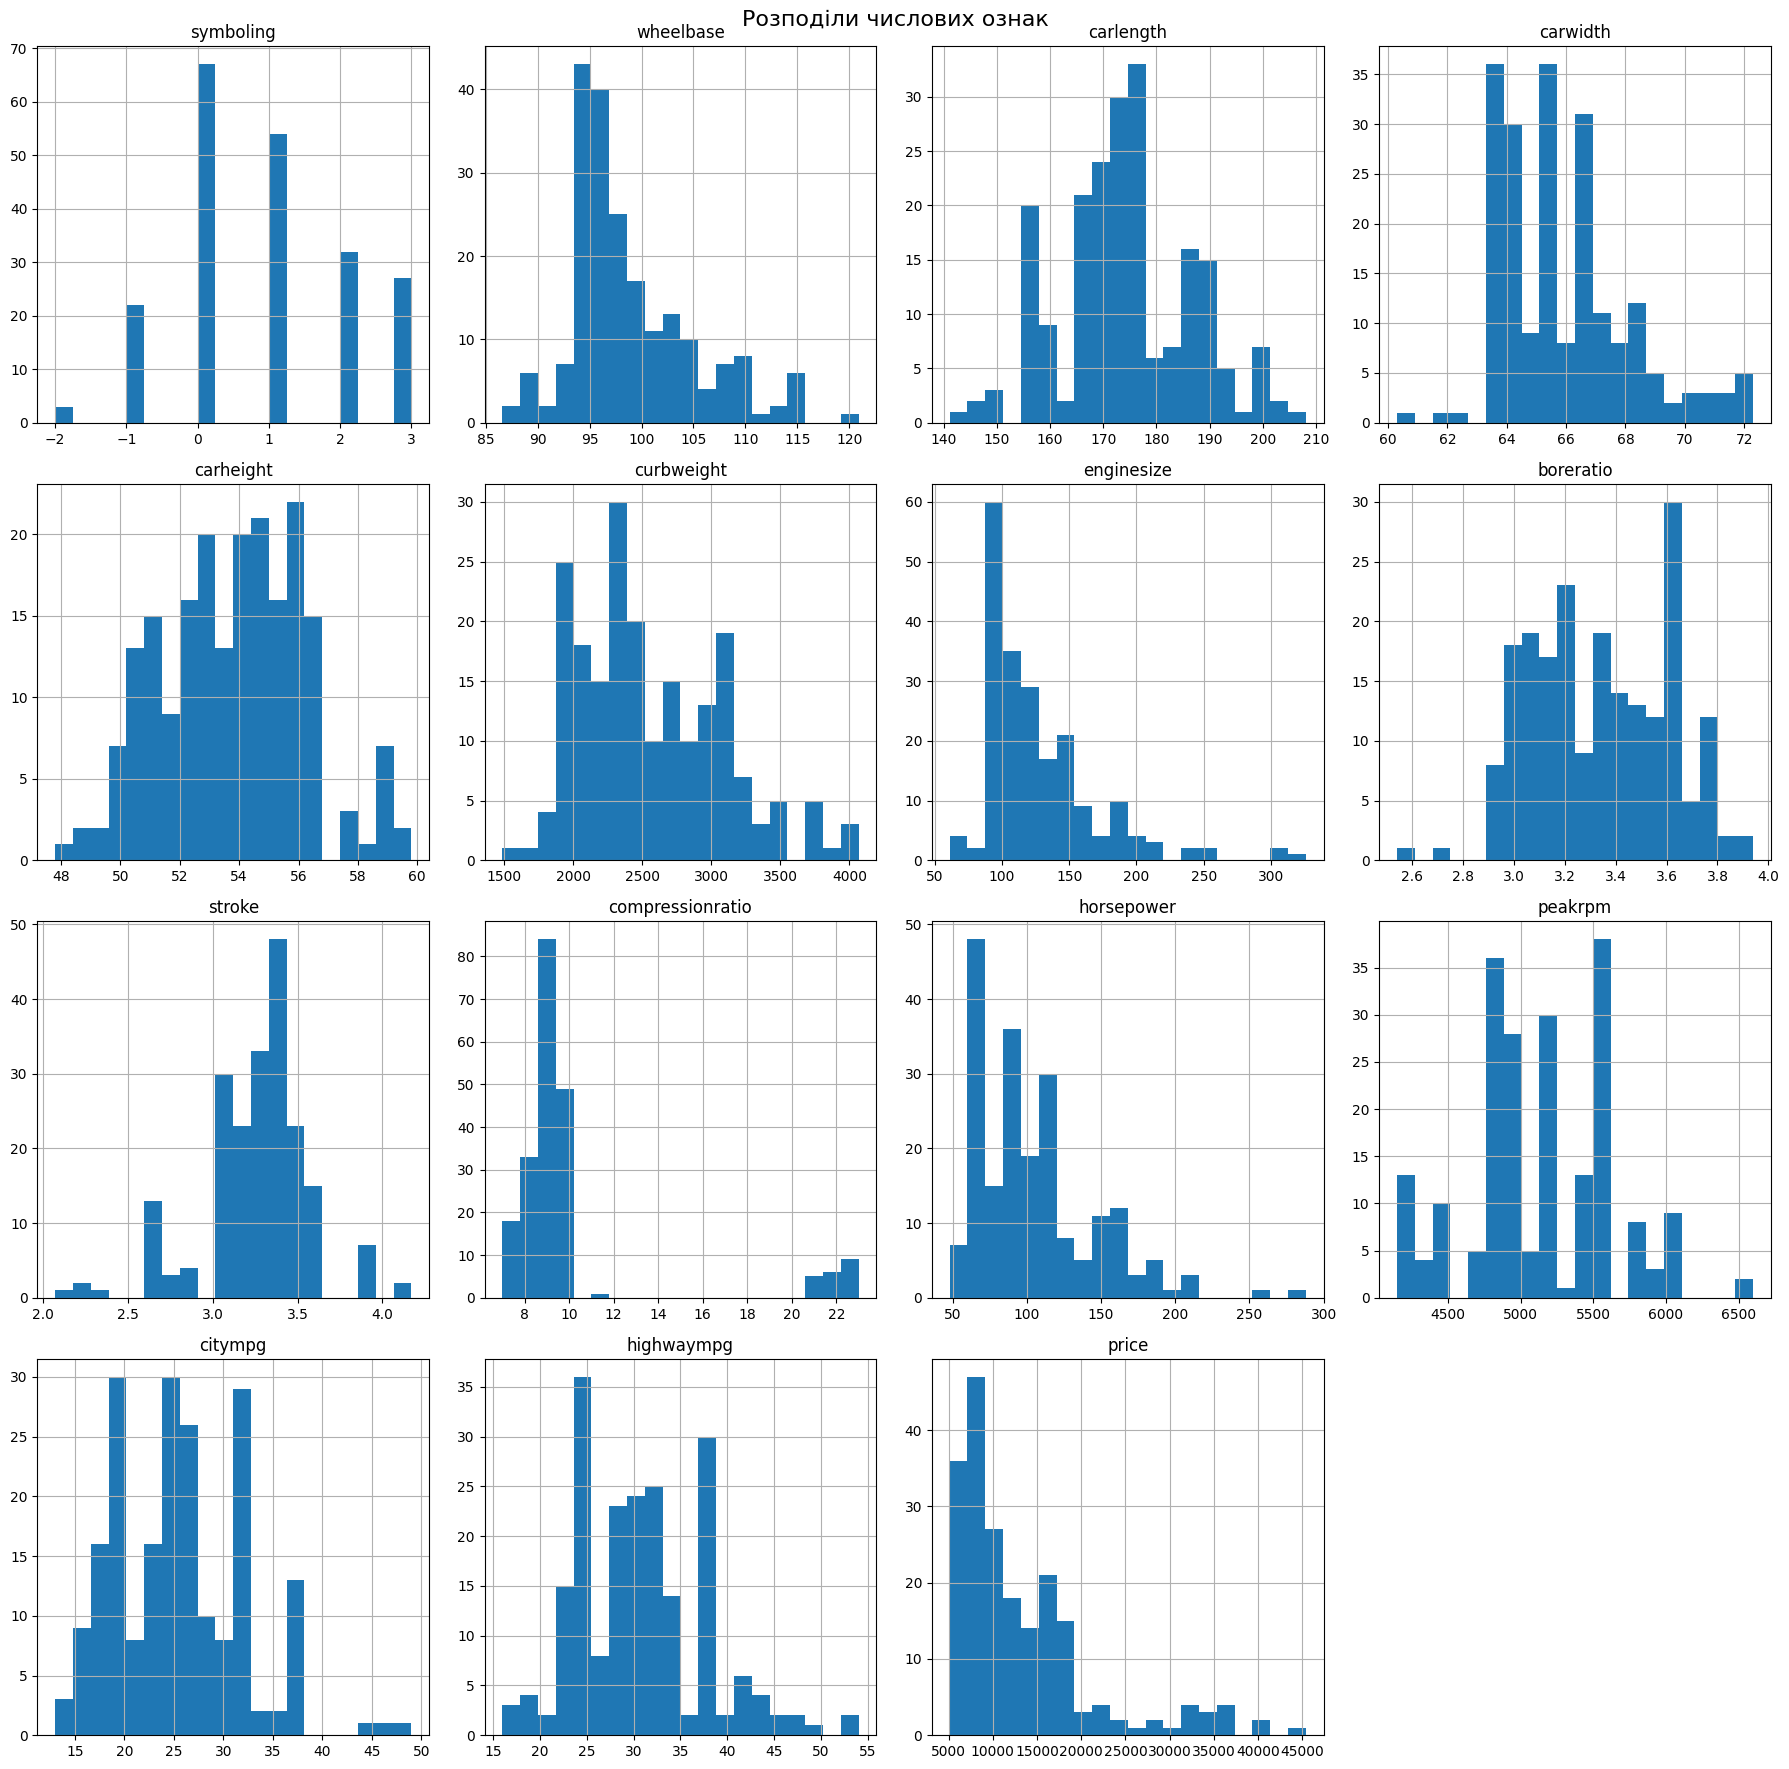

In [7]:
data[numeric_columns].hist(
    figsize=(18, 18),
    bins=20
)

plt.suptitle("Розподіли числових ознак", fontsize=16)
plt.tight_layout()
plt.show()

In [8]:
skewness = data[numeric_columns].skew().sort_values(
    key=lambda x: abs(x),
    ascending=False
)

print("Коефіцієнти асиметрії:")
display(skewness.to_frame("skewness"))

print("\nНайбільш асиметричні ознаки:")
display(skewness.head(10))

Коефіцієнти асиметрії:


,skewness
compressionratio,2.610862
enginesize,1.947655
price,1.777678
horsepower,1.405310
wheelbase,1.050214
carwidth,0.904003
stroke,-0.689705
curbweight,0.681398
citympg,0.663704
highwaympg,0.539997



Найбільш асиметричні ознаки:


,0
compressionratio,2.610862
enginesize,1.947655
price,1.777678
horsepower,1.405310
wheelbase,1.050214
carwidth,0.904003
stroke,-0.689705
curbweight,0.681398
citympg,0.663704
highwaympg,0.539997


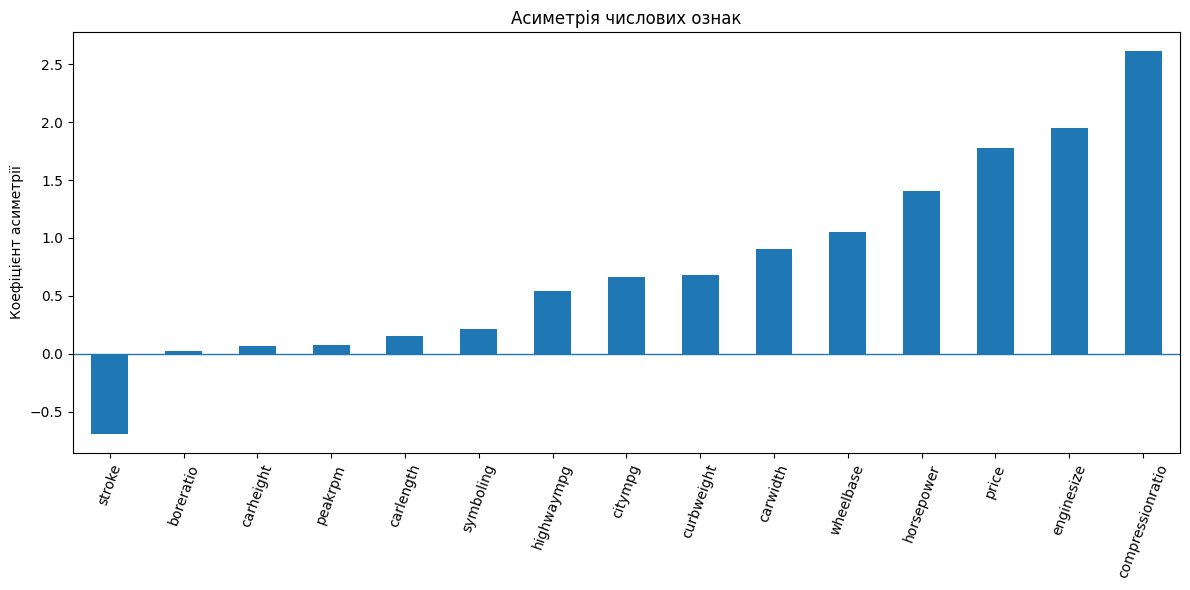

In [9]:
plt.figure(figsize=(12, 6))

skewness.sort_values().plot(kind="bar")

plt.axhline(0, linewidth=1)
plt.title("Асиметрія числових ознак")
plt.ylabel("Коефіцієнт асиметрії")
plt.xticks(rotation=70)
plt.tight_layout()
plt.show()

## 5. Формування train/test вибірок

Відокремити цільову змінну `price` від ознак та розділити дані на:
- навчальну вибірку — 80%;
- тестову вибірку — 20%.

Забезпечити відтворюваність поділу.  
Окремо зберегти `car_ID` для об'єктів, які потрапили до train і test.

**Важливо:** усі подальші параметри передобробки даних визначати тільки за навчальною вибіркою.


In [10]:
X = data.drop(columns=["price"])
y = data["price"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Розмір навчальної вибірки:", X_train.shape)
print("Розмір тестової вибірки:", X_test.shape)

Розмір навчальної вибірки: (164, 24)
Розмір тестової вибірки: (41, 24)


In [11]:
train_ids = car_ids.loc[X_train.index].copy()
test_ids = car_ids.loc[X_test.index].copy()

print("Кількість car_ID у train:", len(train_ids))
print("Кількість car_ID у test:", len(test_ids))

display(test_ids.head())

Кількість car_ID у train: 164
Кількість car_ID у test: 41


,car_ID
15,16
9,10
100,101
132,133
68,69


## 6. Аналіз та обробка викидів

Для неперервних числових ознак навчальної вибірки:
- визначити потенційні викиди методом IQR;
- вивести кількість потенційних викидів для кожної ознаки;
- обґрунтувати спосіб їх обробки.

Для невеликого набору даних не видаляти автоматично всі рядки з викидами. Використати обмеження крайніх значень межами, визначеними за навчальною вибіркою.

Цільову змінну `price` не використовувати для визначення меж викидів.  
До тестової вибірки застосувати ті самі межі, які були отримані за train.


In [12]:
# Визначаємо неперервні числові ознаки
continuous_columns = [
    col for col in X_train.select_dtypes(include=np.number).columns
    if col not in ["symboling"]
]

print("Неперервні числові ознаки:")
print(continuous_columns)

Неперервні числові ознаки:
['wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 'enginesize', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg']


In [13]:
outlier_info = []

for col in continuous_columns:
    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = ((X_train[col] < lower) | (X_train[col] > upper)).sum()

    outlier_info.append({
        "Ознака": col,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Нижня межа": lower,
        "Верхня межа": upper,
        "Кількість викидів": count
    })

outlier_df = pd.DataFrame(outlier_info)

display(
    outlier_df.sort_values(
        "Кількість викидів",
        ascending=False
    )
)

,Ознака,Q1,Q3,IQR,Нижня межа,Верхня межа,Кількість викидів
8,compressionratio,8.600,9.400,0.800,7.4000,10.6000,20
7,stroke,3.110,3.410,0.300,2.6600,3.8600,16
2,carwidth,64.175,66.675,2.500,60.4250,70.4250,10
9,horsepower,71.500,116.000,44.500,4.7500,182.7500,7
5,enginesize,98.000,141.000,43.000,33.5000,205.5000,7
0,wheelbase,94.500,102.100,7.600,83.1000,113.5000,6
10,peakrpm,4800.000,5500.000,700.000,3750.0000,6550.0000,2
12,highwaympg,25.000,34.000,9.000,11.5000,47.5000,1
6,boreratio,3.150,3.540,0.390,2.5650,4.1250,1
4,curbweight,2163.000,2939.250,776.250,998.6250,4103.6250,0


In [14]:
outlier_bounds = {}

for col in continuous_columns:
    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)
    IQR = Q3 - Q1

    outlier_bounds[col] = (
        Q1 - 1.5 * IQR,
        Q3 + 1.5 * IQR
    )

print("Межі IQR визначено тільки за навчальною вибіркою.")

Межі IQR визначено тільки за навчальною вибіркою.


In [15]:
X_train_clipped = X_train.copy()
X_test_clipped = X_test.copy()

for col, (lower, upper) in outlier_bounds.items():
    X_train_clipped[col] = X_train_clipped[col].clip(lower, upper)
    X_test_clipped[col] = X_test_clipped[col].clip(lower, upper)

print("Обробку викидів завершено.")

Обробку викидів завершено.


## 7. Аналіз кореляцій та відбір ознак

За навчальною вибіркою:
- побудувати матрицю кореляцій числових ознак;
- знайти пари ознак із сильною кореляцією, для яких `|r| > 0.85`;
- для кожної такої пари залишити одну ознаку;
- під час вибору врахувати силу зв'язку кожної ознаки з цільовою змінною `price`;
- вивести список сильно корельованих пар та перелік ознак, які видаляються.

Із тестової вибірки видалити ті самі ознаки.  
Не використовувати тестову вибірку для прийняття рішення про відбір ознак.


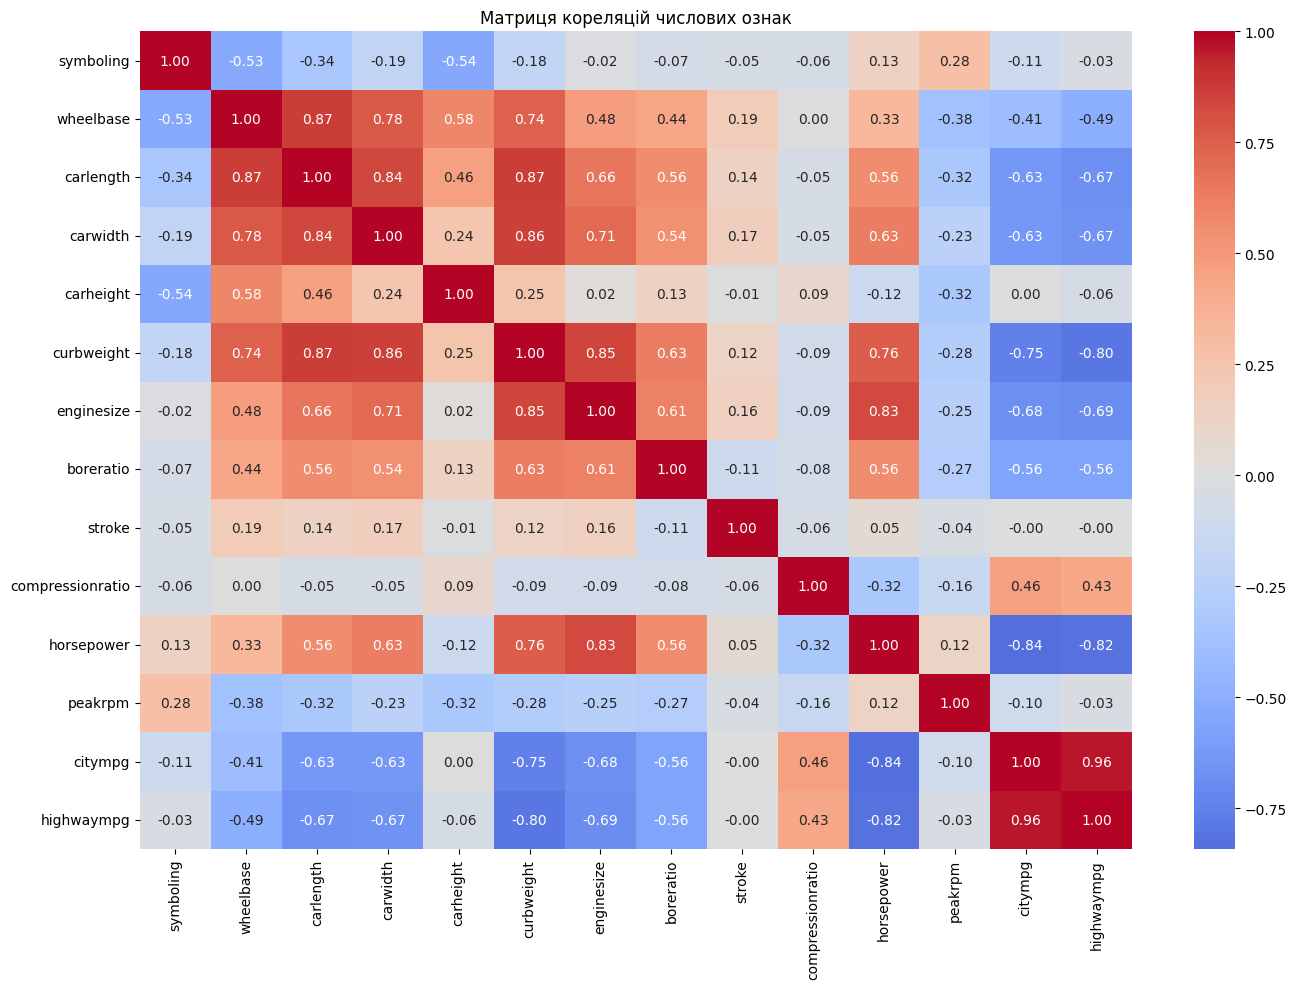

In [16]:
numeric_train = X_train_clipped.select_dtypes(
    include=np.number
).copy()

correlation_matrix = numeric_train.corr()

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Матриця кореляцій числових ознак")
plt.tight_layout()
plt.show()

In [17]:
pairs = []

numeric_predictors = [
    col for col in numeric_train.columns
]

for i in range(len(numeric_predictors)):
    for j in range(i + 1, len(numeric_predictors)):

        col1 = numeric_predictors[i]
        col2 = numeric_predictors[j]

        corr = correlation_matrix.loc[col1, col2]

        if abs(corr) > 0.85:

            corr_price_1 = abs(
                pd.concat(
                    [X_train_clipped[col1], y_train],
                    axis=1
                ).corr().iloc[0, 1]
            )

            corr_price_2 = abs(
                pd.concat(
                    [X_train_clipped[col2], y_train],
                    axis=1
                ).corr().iloc[0, 1]
            )

            if corr_price_1 >= corr_price_2:
                keep = col1
                remove = col2
            else:
                keep = col2
                remove = col1

            pairs.append({
                "Ознака 1": col1,
                "Ознака 2": col2,
                "Кореляція": corr,
                "Залишити": keep,
                "Видалити": remove
            })

correlated_pairs = pd.DataFrame(pairs)

print("Сильно корельовані пари:")
display(correlated_pairs)

Сильно корельовані пари:


,Ознака 1,Ознака 2,Кореляція,Залишити,Видалити
0,wheelbase,carlength,0.867043,carlength,wheelbase
1,carlength,curbweight,0.865988,curbweight,carlength
2,carwidth,curbweight,0.858047,curbweight,carwidth
3,citympg,highwaympg,0.963620,highwaympg,citympg


In [18]:
features_to_remove = set()

if not correlated_pairs.empty:
    features_to_remove = set(
        correlated_pairs["Видалити"]
    )

print("Ознаки, які будуть видалені:")
print(sorted(features_to_remove))

Ознаки, які будуть видалені:
['carlength', 'carwidth', 'citympg', 'wheelbase']


In [19]:
X_train_final = X_train_clipped.drop(
    columns=list(features_to_remove)
)

X_test_final = X_test_clipped.drop(
    columns=list(features_to_remove)
)

print("Розмір X_train після відбору:", X_train_final.shape)
print("Розмір X_test після відбору:", X_test_final.shape)

Розмір X_train після відбору: (164, 20)
Розмір X_test після відбору: (41, 20)


## 8. Підготовка числових і категоріальних ознак

Розділити ознаки на:
- неперервні числові;
- дискретну числову ознаку `symboling`;
- категоріальні.

Для неперервних числових ознак виконати послідовно:
1. перетворення Yeo–Johnson для зменшення асиметрії;
2. масштабування за допомогою StandardScaler.

Для `symboling` виконати масштабування без Yeo–Johnson.

Категоріальні ознаки закодувати методом One-Hot Encoding. Передбачити коректну обробку категорій у test, яких не було у train.

Усі перетворення об'єднати в єдиний механізм передобробки даних, який навчається тільки на `X_train`.


In [20]:
continuous_final = [
    col for col in X_train_final.select_dtypes(include=np.number).columns
    if col != "symboling"
]

if "symboling" in X_train_final.columns:
    discrete_final = ["symboling"]
else:
    discrete_final = []

categorical_final = X_train_final.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Неперервні числові:")
print(continuous_final)

print("\nДискретна числова:")
print(discrete_final)

print("\nКатегоріальні:")
print(categorical_final)

Неперервні числові:
['carheight', 'curbweight', 'enginesize', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'highwaympg']

Дискретна числова:
['symboling']

Категоріальні:
['CarName', 'fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'enginetype', 'cylindernumber', 'fuelsystem']


In [21]:
continuous_pipeline = Pipeline([
    ("yeo_johnson", PowerTransformer(
        method="yeo-johnson",
        standardize=False
    )),
    ("scaler", StandardScaler())
])

transformers = [
    (
        "continuous",
        continuous_pipeline,
        continuous_final
    )
]

if discrete_final:
    transformers.append(
        (
            "symboling",
            StandardScaler(),
            discrete_final
        )
    )

if categorical_final:
    transformers.append(
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_final
        )
    )

preprocessor = ColumnTransformer(
    transformers=transformers,
    remainder="drop"
)

print("Механізм передобробки створено.")

Механізм передобробки створено.


## 9. Перевірка трансформації числових ознак

Перевірити результат трансформації неперервних числових ознак:
- застосувати до train ту саму послідовність перетворень, яка буде використана в моделях;
- повторно обчислити коефіцієнти асиметрії;
- порівняти їх із початковими значеннями;
- зробити короткий висновок щодо ефективності трансформації.


In [22]:
original_skewness = X_train_final[
    continuous_final
].skew()

# Навчаємо трансформер тільки на train
transformer_check = Pipeline([
    ("yeo_johnson", PowerTransformer(
        method="yeo-johnson",
        standardize=False
    )),
    ("scaler", StandardScaler())
])

transformed_values = transformer_check.fit_transform(
    X_train_final[continuous_final]
)

transformed_df = pd.DataFrame(
    transformed_values,
    columns=continuous_final,
    index=X_train_final.index
)

transformed_skewness = transformed_df.skew()

comparison = pd.DataFrame({
    "Початкова асиметрія": original_skewness,
    "Після Yeo-Johnson": transformed_skewness
})

comparison["Зміна абсолютної асиметрії"] = (
    abs(comparison["Початкова асиметрія"])
    - abs(comparison["Після Yeo-Johnson"])
)

display(comparison.sort_values(
    "Зміна абсолютної асиметрії",
    ascending=False
))

,Початкова асиметрія,Після Yeo-Johnson,Зміна абсолютної асиметрії
enginesize,0.962394,0.044834,0.917560
horsepower,0.850735,0.066280,0.784455
curbweight,0.712433,0.049894,0.662539
stroke,-0.397600,0.015846,0.381754
highwaympg,0.243761,-0.012188,0.231574
boreratio,0.062963,-0.005941,0.057021
compressionratio,0.055710,0.004872,0.050838
peakrpm,0.039773,-0.003589,0.036184
carheight,0.028154,-0.005170,0.022984


## 10. Побудова регресійних моделей

Побудувати та навчити такі моделі:
- Linear Regression;
- Ridge Regression;
- Lasso Regression;
- Random Forest Regressor;
- Gradient Boosting Regressor;
- Support Vector Regressor (SVR).

Для кожної моделі створити єдиний Pipeline, який містить:
1. попередню обробку ознак;
2. відповідну регресійну модель.

Використати однакову схему підготовки даних для коректного порівняння моделей.


In [23]:
models = {
    "Linear Regression": LinearRegression(),

    "Ridge Regression": Ridge(
        alpha=1.0
    ),

    "Lasso Regression": Lasso(
        alpha=0.01,
        max_iter=10000
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ),

    "SVR": SVR(
        kernel="rbf",
        C=100,
        epsilon=0.1
    )
}

In [24]:
pipelines = {}

for name, model in models.items():

    pipelines[name] = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

print("Створено Pipeline для моделей:")

for name in pipelines:
    print("-", name)

Створено Pipeline для моделей:
- Linear Regression
- Ridge Regression
- Lasso Regression
- Random Forest
- Gradient Boosting
- SVR


In [25]:
for name, pipeline in pipelines.items():

    pipeline.fit(
        X_train_final,
        y_train
    )

    print(f"{name}: модель навчено.")

print("\nНавчання всіх моделей завершено.")

Linear Regression: модель навчено.
Ridge Regression: модель навчено.
Lasso Regression: модель навчено.
Random Forest: модель навчено.
Gradient Boosting: модель навчено.
SVR: модель навчено.

Навчання всіх моделей завершено.


## 11. Оцінювання якості моделей

Для кожної моделі:
- виконати навчання на тренувальній вибірці;
- отримати прогноз для тестової вибірки;
- обчислити метрики **R², MAE, MSE та MAPE**.

`MAPE` подати у відсотках.

Результати всіх моделей об'єднати в одну порівняльну таблицю та впорядкувати за значенням R² від найбільшого до найменшого.

Під час інтерпретації врахувати:
- R² — чим більше, тим краще;
- MAE, MSE, MAPE — чим менше, тим краще.


In [26]:
results = []

predictions = {}

for name, pipeline in pipelines.items():

    y_pred = pipeline.predict(X_test_final)

    predictions[name] = y_pred

    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    mape = mean_absolute_percentage_error(
        y_test,
        y_pred
    ) * 100

    results.append({
        "Модель": name,
        "R²": r2,
        "MAE": mae,
        "MSE": mse,
        "MAPE (%)": mape
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    "R²",
    ascending=False
).reset_index(drop=True)

display(
    results_df.style.format({
        "R²": "{:.4f}",
        "MAE": "{:.2f}",
        "MSE": "{:.2f}",
        "MAPE (%)": "{:.2f}"
    })
)

,Модель,R²,MAE,MSE,MAPE (%)
0,Random Forest,0.9509,1424.40,3873485.24,10.34
1,Gradient Boosting,0.9273,1720.46,5740707.82,12.99
2,Ridge Regression,0.7957,2712.77,16129423.33,23.07
3,Linear Regression,0.5481,4078.23,35676914.46,29.97
4,Lasso Regression,0.4557,4181.46,42969211.93,29.03
5,SVR,0.1075,4578.15,70456877.60,25.86


## 12. Пояснення вибору типу моделі

Пояснити, чому класифікаційна модель, наприклад Logistic Regression, не підходить для безпосереднього прогнозування неперервної ціни автомобіля.

Зазначити, до якого типу задачі належить прогнозування `price` та чому моделі, використані в роботі, відповідають цій задачі.


Відповідь: Прогнозування ціни автомобіля є задачею регресії, оскільки цільова змінна price має неперервне числове значення. Регресійні моделі призначені саме для прогнозування числових величин.

Logistic Regression для цієї задачі безпосередньо не підходить, оскільки вона використовується переважно для класифікації об'єктів за категоріями. У цій лабораторній роботі необхідно прогнозувати конкретне числове значення ціни, тому були використані Linear Regression, Ridge, Lasso, Random Forest Regressor, Gradient Boosting Regressor та SVR.

## 13. Візуальне порівняння прогнозів

Для кожної побудованої моделі зобразити співвідношення:
- фактичних значень `price`;
- прогнозованих значень `price`.

Додати лінію ідеального прогнозу та проаналізувати, наскільки близько до неї розташовані прогнозовані значення. Звернути увагу на великі відхилення.


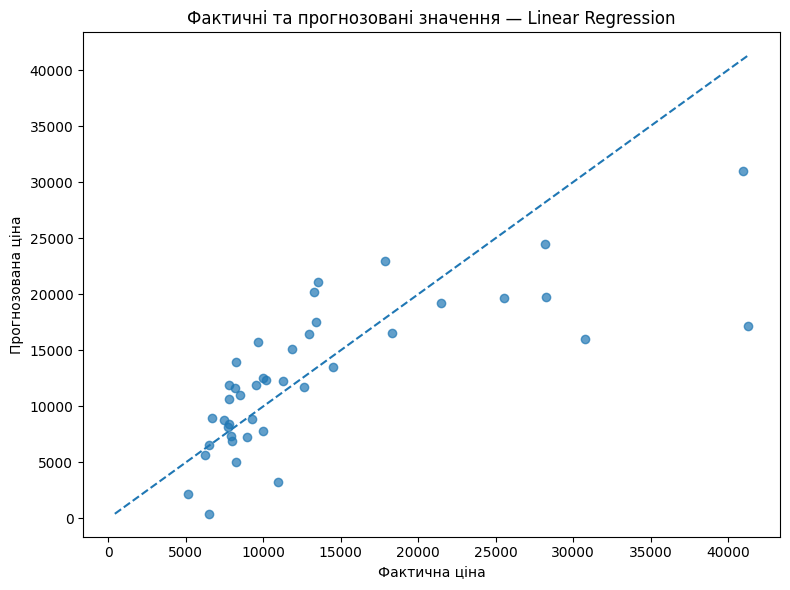

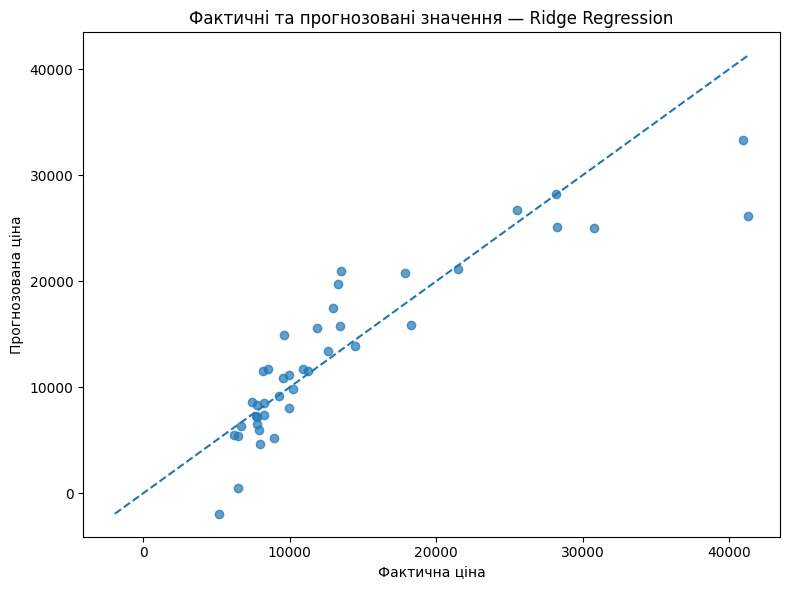

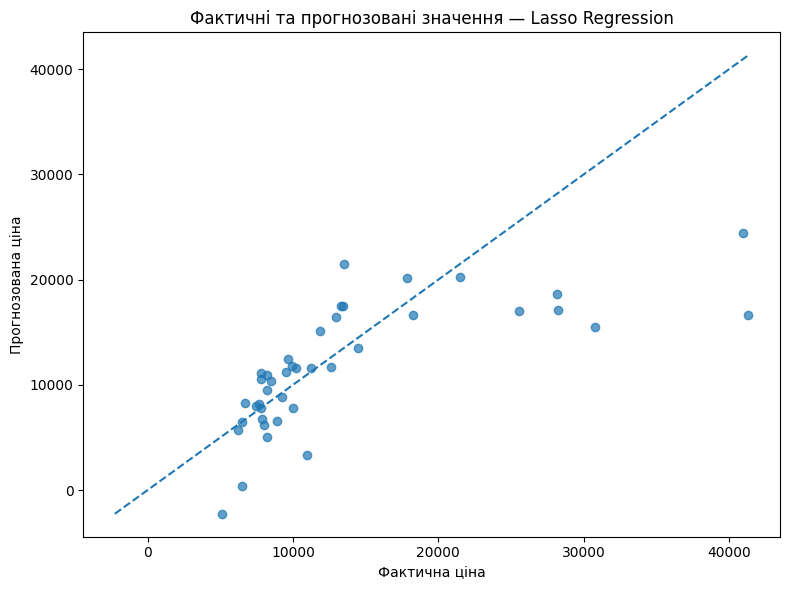

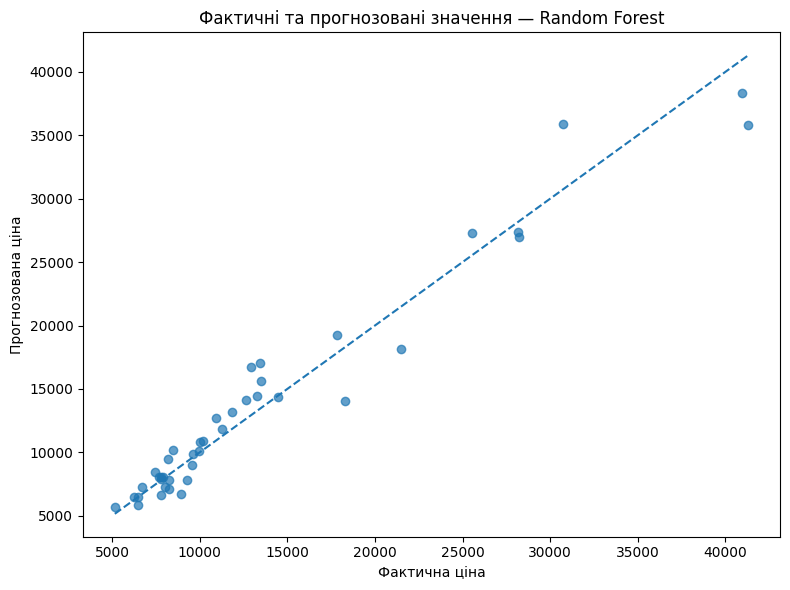

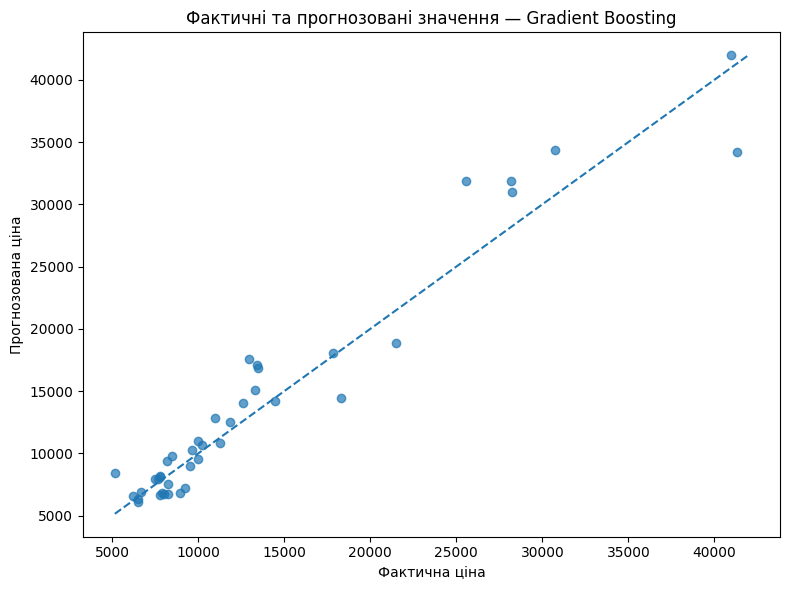

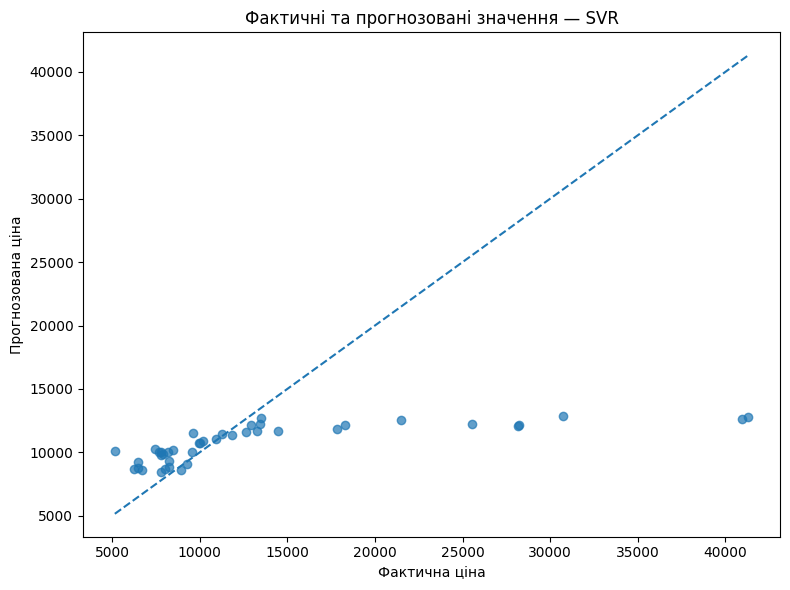

In [27]:
for name, y_pred in predictions.items():

    plt.figure(figsize=(8, 6))

    plt.scatter(
        y_test,
        y_pred,
        alpha=0.7
    )

    min_value = min(
        y_test.min(),
        y_pred.min()
    )

    max_value = max(
        y_test.max(),
        y_pred.max()
    )

    plt.plot(
        [min_value, max_value],
        [min_value, max_value],
        linestyle="--"
    )

    plt.xlabel("Фактична ціна")
    plt.ylabel("Прогнозована ціна")
    plt.title(
        f"Фактичні та прогнозовані значення — {name}"
    )

    plt.tight_layout()
    plt.show()

## 14. Прогноз для 10 автомобілів

Випадково вибрати 10 автомобілів із тестової вибірки.

За допомогою моделі Random Forest отримати для них прогноз ціни та сформувати таблицю з такими даними:
- `car_ID`;
- фактична ціна;
- прогнозована ціна;
- абсолютна помилка;
- абсолютна відсоткова помилка.

Прокоментувати отримані результати.


In [28]:
# Випадково вибираємо 10 автомобілів із тестової вибірки
sample_indices = X_test_final.sample(
    n=10,
    random_state=42
).index

X_sample = X_test_final.loc[sample_indices]
y_sample = y_test.loc[sample_indices]
ids_sample = test_ids.loc[sample_indices]

# Прогноз Random Forest
rf_predictions = pipelines["Random Forest"].predict(
    X_sample
)

prediction_table = pd.DataFrame({
    "car_ID": ids_sample.values,
    "Фактична ціна": y_sample.values,
    "Прогнозована ціна": rf_predictions
})

prediction_table["Абсолютна помилка"] = (
    abs(
        prediction_table["Фактична ціна"]
        - prediction_table["Прогнозована ціна"]
    )
)

prediction_table["Абсолютна відсоткова помилка (%)"] = (
    prediction_table["Абсолютна помилка"]
    / prediction_table["Фактична ціна"]
    * 100
)

display(
    prediction_table.style.format({
        "Фактична ціна": "{:.2f}",
        "Прогнозована ціна": "{:.2f}",
        "Абсолютна помилка": "{:.2f}",
        "Абсолютна відсоткова помилка (%)": "{:.2f}"
    })
)

,car_ID,Фактична ціна,Прогнозована ціна,Абсолютна помилка,Абсолютна відсоткова помилка (%)
0,26,6692.00,7256.92,564.92,8.44
1,176,9988.00,10805.55,817.55,8.19
2,148,10198.00,10871.77,673.77,6.61
3,17,41315.00,35845.66,5469.34,13.24
4,69,28248.00,26983.71,1264.29,4.48
5,147,7463.00,8422.47,959.47,12.86
6,144,9960.00,10085.13,125.13,1.26
7,85,14489.00,14357.93,131.07,0.90
8,195,12940.00,16727.40,3787.40,29.27
9,160,7788.00,7867.79,79.79,1.02


In [29]:
print(
    "Середня абсолютна помилка:",
    round(
        prediction_table["Абсолютна помилка"].mean(),
        2
    )
)

print(
    "Середня абсолютна відсоткова помилка:",
    round(
        prediction_table[
            "Абсолютна відсоткова помилка (%)"
        ].mean(),
        2
    ),
    "%"
)

Середня абсолютна помилка: 1387.27
Середня абсолютна відсоткова помилка: 8.63 %


## 15. Висновки

Сформулювати підсумкові висновки за результатами роботи.

У висновках:
- порівняти якість усіх моделей;
- проаналізувати R², MAE, MSE і MAPE;
- зазначити, яка модель показала найкращі результати за отриманими метриками;
- прокоментувати величину похибок;
- звернути увагу на можливі ознаки перенавчання;
- коротко оцінити вплив попередньої обробки даних на результати моделювання.


Висновок: Під час виконання лабораторної роботи було проведено повне дослідження даних про автомобілі та побудовано декілька регресійних моделей для прогнозування їхньої ціни. На першому етапі було виконано первинний аналіз датасету, визначено структуру даних, типи ознак та цільову змінну price. Ідентифікатор car_ID було збережено окремо та не використовувалося під час навчання моделей.

Далі було перевірено якість даних, пропущені значення, дублікати та кількість унікальних значень. Числові ознаки було досліджено за допомогою графіків і коефіцієнтів асиметрії. Дані поділено на навчальну та тестову вибірки у співвідношенні 80/20.

Для обробки потенційних викидів використано метод IQR. Рядки з викидами не видалялися, а крайні значення обмежувалися межами, визначеними за навчальною вибіркою. Також було виконано кореляційний аналіз та видалено надлишкові ознаки із сильною взаємною кореляцією.

Для підготовки даних використано перетворення Yeo–Johnson, StandardScaler та One-Hot Encoding. Усі параметри передобробки визначалися тільки на навчальній вибірці, що дозволило уникнути використання інформації з тестових даних під час навчання.

Було побудовано шість моделей: Linear Regression, Ridge Regression, Lasso Regression, Random Forest Regressor, Gradient Boosting Regressor та Support Vector Regressor. Їх якість оцінювалася за допомогою R², MAE, MSE та MAPE. За отриманими результатами модель Random Forest показала найкраще поєднання показників на тестовій вибірці. Найменші значення MAE, MSE та MAPE свідчать про менші помилки прогнозування, а вище значення R² — про кращу відповідність прогнозів фактичним значенням.

Також було побудовано графіки фактичних і прогнозованих цін та виконано окремий прогноз для десяти автомобілів із тестової вибірки. Це дозволило додатково оцінити величину похибок на конкретних прикладах. Загалом попередня обробка даних, відбір ознак та використання різних алгоритмів регресії дали можливість провести комплексне порівняння моделей і визначити їхню ефективність для прогнозування ціни автомобілів.

## Загальні вимоги до виконання

- Не використовувати тестову вибірку для визначення меж викидів, кореляційного відбору ознак, навчання трансформерів, масштабування або кодування категорій.
- Усі параметри передобробки мають визначатися тільки за навчальною вибіркою.
- Фінальні метрики моделей обчислювати на тестовій вибірці.
- Не використовувати `car_ID` як предиктор.
- Не видаляти спостереження або ознаки без пояснення причини.
- До кожного основного етапу додати короткий змістовний висновок.
- У підсумкових висновках спиратися на отримані метрики та графіки.
